# ขั้นที่ 3b: แผนที่ทำนายทั่วประเทศ (กริด 5 กม.)

ใช้โมเดลตัวจริงจาก notebook 10 ทำนายทุกจุดของกริด 5 กม. บนแผ่นดินไทย (~20,700 จุด) ด้วย feature ชุดเดียวกับตอน train
(พันเจีย + DEM + ธรณีวิทยา + Sentinel-2 ที่ดึงด้วยกติกาเลือกภาพเดียวกัน)

- **แผนที่โอกาสพบซาก** (ขั้น A) ทั้ง `bg_bias` และ `bg_uniform` เทียบกัน
- **แผนที่ประเภทซาก** (ขั้น B) แยกทีละประเภท (small multiples) เพราะประเภทมีมากเกินจะแยกด้วยสีเดียวในแผนที่เดียว
- ใช้**โมเดลตารางอย่างเดียว** ตามที่ตกลงหลัง notebook 10 (`final_meta.json` → `deploy`): เฉลี่ยกับ CNN ทำให้ผลแย่ลง
- ตรวจแบบ Block et al. 2016 อีกครั้ง โดยใช้จุดกริดเป็น "ตำแหน่งสุ่ม" เทียบกับ PBDB

**รันต่อได้**: feature ของกริดเก็บใน `data/features/sat_cache/grid_*`, patch ใน `data/features/s2/grid_patches/`

In [1]:
import sys

sys.path.insert(0, ".")
import model_lib as ml
import feature_lib as fl

import json

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
INK, MUTED = "#52514e", "#8a8984"
FINAL = ml.MODELS / "task2" / "final"
meta = json.loads((FINAL / "final_meta.json").read_text(encoding="utf-8"))
grid = pd.read_parquet(fl.FEAT / "grid_5km.parquet")
print(f"กริด {len(grid):,} จุด | คลาสขั้น B: {meta['classes_B']}")

กริด 20,706 จุด | คลาสขั้น B: ['ไดโนเสาร์', 'สัตว์เลื้อยคลานอื่น', 'ปลา', 'สัตว์เลี้ยงลูกด้วยนม', 'แบรคิโอพอด', 'หอยสองฝา', 'หอยฝาเดียว', 'เซฟาโลพอด', 'ปะการัง', 'ไครนอยด์', 'ไบรโอซัว', 'ไทรโลไบต์', 'แกรปโตไลต์', 'ฟอแรม/ฟิวซูลินิด', 'พืช', 'ร่องรอย']


## 1. feature ของกริด (ใช้ cache; ดึง Sentinel-2 ที่ยังขาด)

In [2]:
pg = fl.batch_pangea(grid, tag="grid_")
geo = fl.batch_geology(grid, tag="grid_")
dem = fl.batch_dem(grid, tag="grid_")
S2DIR = fl.FEAT / "s2"
items = pd.read_parquet(S2DIR / "items.parquet")
asg = fl.scene_assignment(grid, items, cache_file=S2DIR / "assignment_grid_patches.parquet", workers=12)
fl.fetch_patches_batch(grid, items, asg, S2DIR / "grid_patches", workers=12)
s2 = fl.batch_s2_indices(grid, S2DIR / "grid_patches", tag="grid_")
G = grid.merge(pg, on="point_id").merge(dem, on="point_id").merge(geo, on="point_id").merge(s2, on="point_id", how="left")
for c in ["pg_sw18_plate", "pg_me21_plate", "pg_me21_terrane", "geo_rock_sym", "geo_era_old", "geo_era_young", "geo_rock_kind", "oc_nearest_rock"]:
    if c in G:
        G[c] = G[c].astype(str)
DEPLOY = meta["deploy"]
GP, ok = ml.load_patches(G.point_id.values, S2DIR / "grid_patches") if DEPLOY["use_cnn"] else (None, G.s2_B02_mean.notna().values)
print(f"กริดที่มีภาพ Sentinel-2: {ok.mean():.1%} | ค่าว่างใน feature หลัก: {int(G[meta['features']['num']].isna().any(axis=1).sum())} จุด")
print("ใช้:", DEPLOY)

# ขั้น A แบบ feature engineering ที่ตกลงหลัง notebook 14: + ธรณี+ / ผิวดิน (notebook 13) + บริบทเชิงพื้นที่
# (จากแหล่ง ทธ. ทั้งหมด ยกเว้นแหล่งในบล็อก 50 กม. เดียวกับจุด — แบบเดียวกับตอน train)
STAGE_A_FE = DEPLOY.get("stage_A_variant") == "fe"
REF = (pd.read_parquet(ml.FEAT / "all_features.parquet").merge(pd.read_parquet(ml.FEAT / "folds.parquet"), on="point_id")
       .query("source == 'dmr_site'").assign(geo_rock_sym=lambda d: d.geo_rock_sym.astype(str)))
if STAGE_A_FE:
    META_FE = json.loads((FINAL / "final_meta_fe.json").read_text(encoding="utf-8"))
    G = G.merge(pd.read_parquet(fl.FEAT / "extra_grid.parquet"), on="point_id", how="left")
    G = pd.concat([G, fl.spatial_context(G, REF, fl.block_group(G.lon, G.lat), REF.group_spatial_block.values)], axis=1)
    STAGE_A = META_FE["stage_A"]
else:
    STAGE_A = meta["stage_A"]
print("ขั้น A:", {bg: STAGE_A[bg]["tabular"] for bg in DEPLOY["backgrounds"]})

DEM (chunk): 100%|██████████| 42/42 [00:00<00:00, 503.68it/s]
ดัชนี Sentinel-2: 0it [00:00, ?it/s]


กริดที่มีภาพ Sentinel-2: 100.0% | ค่าว่างใน feature หลัก: 25 จุด
ใช้: {'backgrounds': ['bg_bias', 'bg_uniform'], 'default_background': 'bg_bias', 'use_cnn': False, 'stage_A_variant': 'base'}
ขั้น A: {'bg_bias': 'A_bg_bias_xgb.joblib', 'bg_uniform': 'A_bg_uniform_xgb.joblib'}


## 2. ทำนาย

In [3]:
def predict(stage, X, P=None):
    # โมเดลตาราง (+ เฉลี่ยกับ CNN ถ้า deploy.use_cnn) — จุดที่ไม่มีภาพใช้โมเดลตารางอย่างเดียว
    p = ml.predict_bundle(FINAL / stage["tabular"], X)
    if DEPLOY["use_cnn"] and P is not None:
        pc = ml.predict_bundle(FINAL / stage["cnn"], P)
        p = np.where(ok if p.ndim == 1 else ok[:, None], (p + pc) / 2, p)
    return p


BGS, BG = DEPLOY["backgrounds"], DEPLOY["default_background"]
for bg in ml.tqdm_auto()(BGS, desc="ขั้น A"):
    G[f"potential_{bg}"] = predict(STAGE_A[bg], G, GP)
    G[f"rank_{bg}"] = G[f"potential_{bg}"].rank(pct=True)
G["potential"] = G[f"potential_{BG}"]
PBm = predict(meta["stage_B"], G, GP)
for j, c in enumerate(meta["classes_B"]):
    G[f"type_{c}"] = PBm[:, j]
G["top_type"] = [meta["classes_B"][i] for i in PBm.argmax(axis=1)]
# ขอบเขตที่โมเดลใช้ได้ (AOA จาก notebook 10): นอกขอบเขต = feature ต่างจากข้อมูล train เกินเกณฑ์
AOAS = {k: ml.joblib.load(FINAL / v) for k, v in meta["aoa"].items()}
if STAGE_A_FE:
    AOAS.update({f"A_{bg}": ml.joblib.load(FINAL / STAGE_A[bg]["aoa"]) for bg in BGS})
for bg in BGS:
    G[f"di_{bg}"] = AOAS[f"A_{bg}"].di(G)
    G[f"inside_{bg}"] = G[f"di_{bg}"] <= AOAS[f"A_{bg}"].threshold_
G["inside_B"] = AOAS["B"].inside(G)
print("สัดส่วนกริดในขอบเขต:", {k: f"{G[k].mean():.1%}" for k in [f"inside_{bg}" for bg in BGS] + ["inside_B"]})
display(G[[f"potential_{bg}" for bg in BGS]].describe().round(3).T)
print(f"สหสัมพันธ์อันดับระหว่างสองแบบ (Spearman): {G[f'potential_{BGS[0]}'].corr(G[f'potential_{BGS[-1]}'], method='spearman'):.2f}")

ขั้น A: 100%|██████████| 2/2 [00:00<00:00, 15.72it/s]


สัดส่วนกริดในขอบเขต: {'inside_bg_bias': '93.3%', 'inside_bg_uniform': '98.9%', 'inside_B': '75.2%'}


,count,mean,std,min,25%,50%,75%,max
potential_bg_bias,20706.0,0.069,0.138,0.0,0.005,0.016,0.057,0.987
potential_bg_uniform,20706.0,0.067,0.161,0.0,0.002,0.007,0.035,0.996


สหสัมพันธ์อันดับระหว่างสองแบบ (Spearman): 0.78


In [4]:
allf = pd.read_parquet(ml.FEAT / "all_features.parquet")
CATS = ["pg_sw18_plate", "pg_me21_plate", "pg_me21_terrane", "geo_rock_sym", "geo_era_old", "geo_era_young", "geo_rock_kind", "oc_nearest_rock"]
pb = allf[allf.source.eq("pbdb")].pipe(lambda d: d.assign(**{c: d[c].astype(str) for c in CATS})).reset_index(drop=True)
if STAGE_A_FE:
    pb = pb.merge(pd.read_parquet(ml.FEAT / "extra_features.parquet"), on="point_id", how="left")
    pb = pd.concat([pb, fl.spatial_context(pb, REF, fl.block_group(pb.lon, pb.lat), REF.group_spatial_block.values)], axis=1)
dmr = allf[allf.source.eq("dmr_site")]
# PBDB ที่ไม่เคยใช้ train vs ตำแหน่งสุ่ม (= ทุกจุดกริดบนแผ่นดิน) — ยุติธรรมกว่าเทียบกับ background ที่ใช้ train (ใช้โมเดลตาราง)
rows = []
for bg in BGS:
    s_pb = ml.predict_bundle(FINAL / STAGE_A[bg]["tabular"], pb)
    g = G[f"potential_{bg}"].values
    rows.append({"background": bg, "KS (Block 2016)": ml.ks_vs_random(s_pb, g),
                 "AUC PBDB vs กริด": ml.roc_auc_score(np.r_[np.ones(len(s_pb)), np.zeros(len(g))], np.r_[s_pb, g]),
                 "PBDB ในพื้นที่ 10% บนสุด": np.mean(s_pb >= np.quantile(g, 0.9)),
                 "PBDB ในพื้นที่ 25% บนสุด": np.mean(s_pb >= np.quantile(g, 0.75)),
                 "PBDB ในขอบเขต (AOA)": AOAS[f"A_{bg}"].inside(pb).mean()})
pd.DataFrame(rows).set_index("background").style.format("{:.3f}")

,KS (Block 2016),AUC PBDB vs กริด,PBDB ในพื้นที่ 10% บนสุด,PBDB ในพื้นที่ 25% บนสุด,PBDB ในขอบเขต (AOA)
background,,,,,
bg_bias,0.474,0.796,0.479,0.693,0.924
bg_uniform,0.506,0.814,0.552,0.748,0.952


## 3. แผนที่

Text(0.01, 0.98, 'โอกาสพบซากดึกดำบรรพ์ทั่วประเทศ (กริด 5 กม., โมเดลตาราง)')

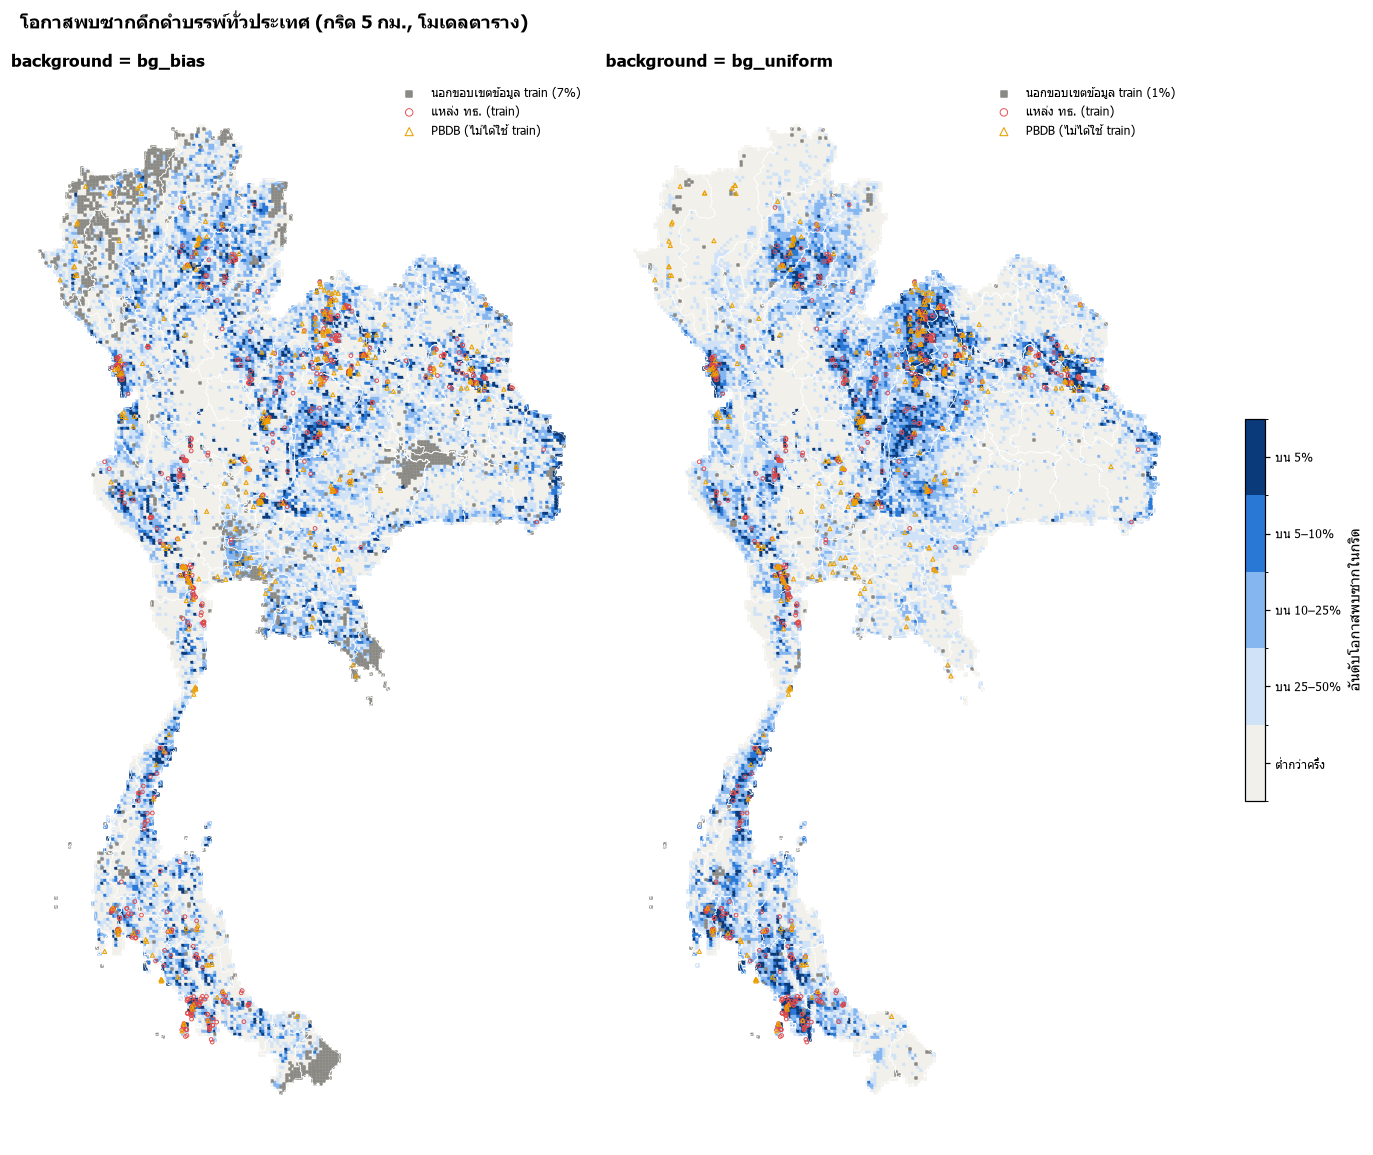

In [5]:
prov = gpd.read_file(fl.DATA / "dmr_admin" / "provinces.geojson")
# แบ่งเป็นช่วงอันดับในกริด: ความน่าจะเป็นของสองแบบสเกลต่างกัน และส่วนใหญ่ของประเทศมีค่าใกล้ 0
# จึงแสดง "ควรสำรวจตรงไหนก่อน" ด้วยช่วงบนสุด 5 / 10 / 25 / 50 %
from matplotlib.colors import BoundaryNorm, ListedColormap

BINS = [0, 50, 75, 90, 95, 100.001]
BIN_LABELS = ["ต่ำกว่าครึ่ง", "บน 25–50%", "บน 10–25%", "บน 5–10%", "บน 5%"]
CMAP = ListedColormap(["#f1f0eb", "#cfe2f7", "#86b6ef", "#2a78d6", "#0b3a7a"])
fig, axes = plt.subplots(1, len(BGS), figsize=(6.2 * len(BGS), 10.5), constrained_layout=True)
for ax, bg in zip(np.atleast_1d(axes), BGS):
    ins = G[f"inside_{bg}"]
    sc = ax.scatter(G.lon[ins], G.lat[ins], c=G[f"rank_{bg}"][ins] * 100, s=3.4, marker="s", cmap=CMAP, norm=BoundaryNorm(BINS, CMAP.N), zorder=0)
    ax.scatter(G.lon[~ins], G.lat[~ins], s=3.4, marker="s", color="#8a8984", zorder=0, label=f"นอกขอบเขตข้อมูล train ({(~ins).mean():.0%})")
    prov.boundary.plot(ax=ax, color="#ffffff", linewidth=0.35, zorder=1)
    ax.scatter(dmr.lon, dmr.lat, s=6, facecolor="none", edgecolor="#e34948", linewidth=0.6, label="แหล่ง ทธ. (train)", zorder=2)
    ax.scatter(pb.lon, pb.lat, s=7, marker="^", facecolor="none", edgecolor="#eda100", linewidth=0.7, label="PBDB (ไม่ได้ใช้ train)", zorder=2)
    ax.set_axis_off()
    ax.set_title(f"background = {bg}", loc="left", fontweight="bold", fontsize=11)
for ax in np.atleast_1d(axes):
    ax.legend(loc="upper right", frameon=False, fontsize=8, markerscale=2)
cb = fig.colorbar(sc, ax=axes, shrink=0.35, ticks=[(BINS[i] + min(BINS[i + 1], 100)) / 2 for i in range(len(BIN_LABELS))])
cb.ax.set_yticklabels(BIN_LABELS, fontsize=8)
cb.set_label("อันดับโอกาสพบซากในกริด")
fig.suptitle("โอกาสพบซากดึกดำบรรพ์ทั่วประเทศ (กริด 5 กม., โมเดลตาราง)", x=0.01, ha="left", fontweight="bold")

Text(0.01, 0.98, 'โอกาสพบซากแต่ละประเภท (โอกาสพบซาก [bg_bias] × ความน่าจะเป็นของประเภท; สีเทา = นอกขอบเขตข้อมูล train)')

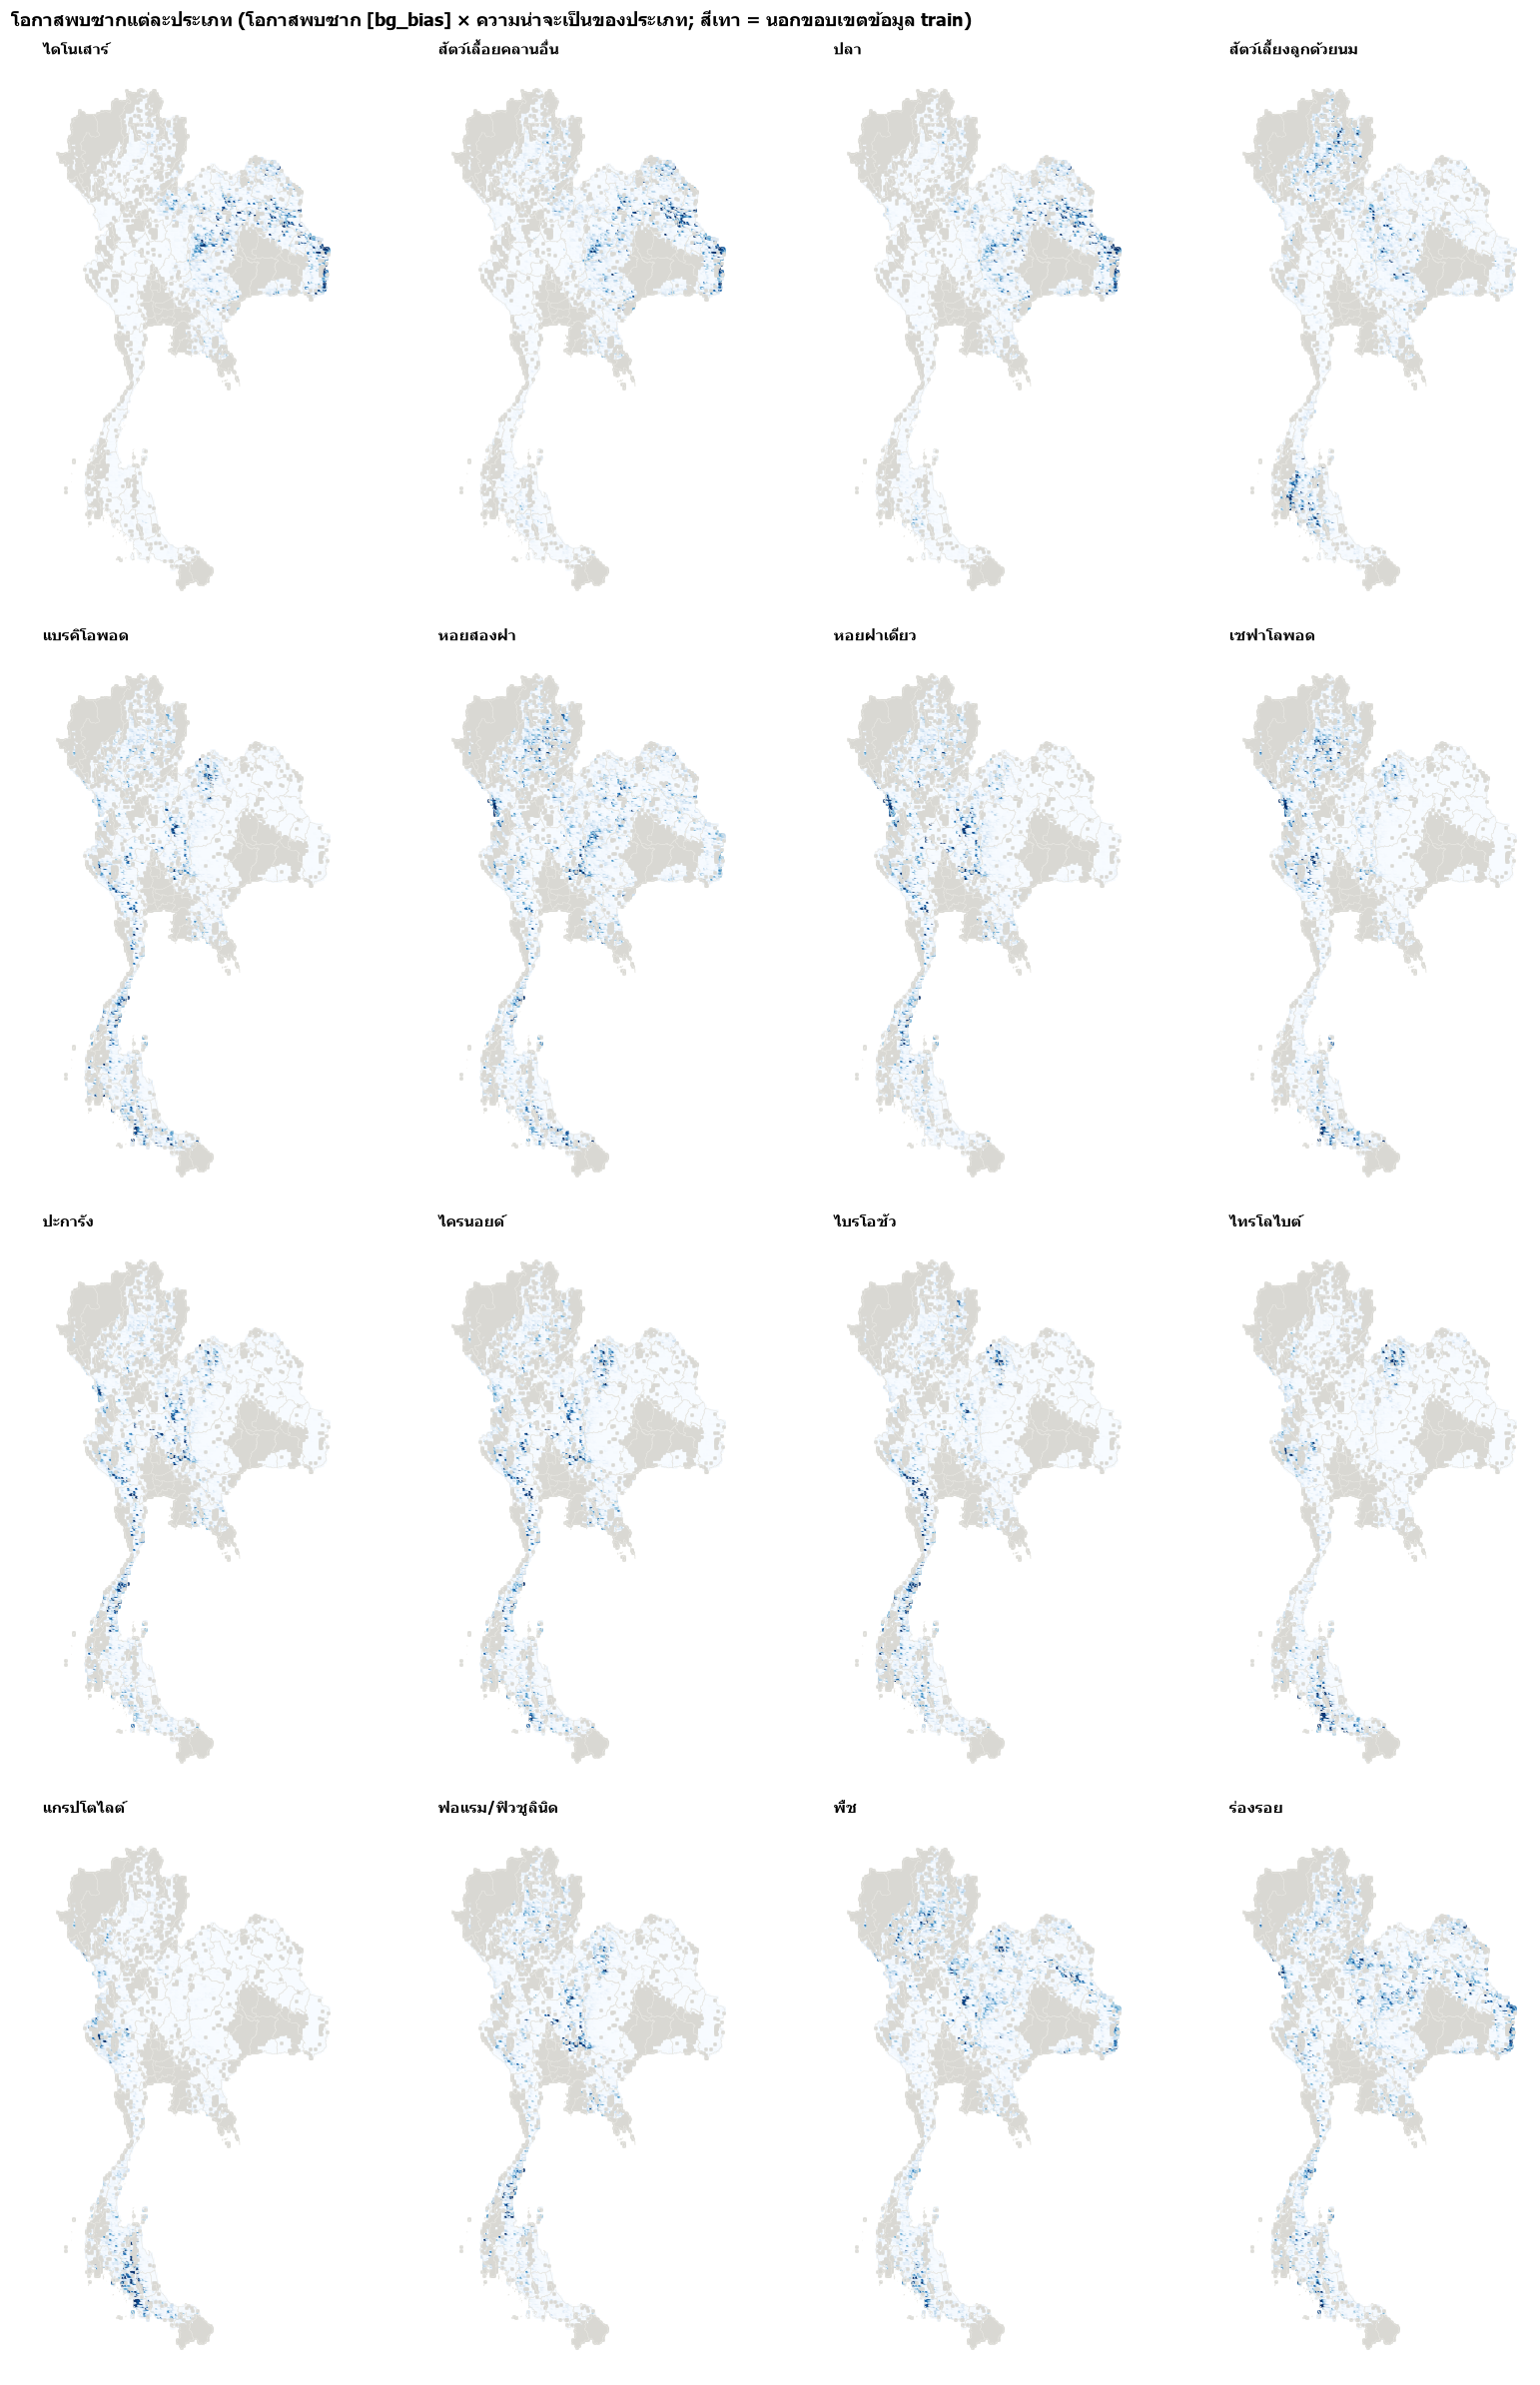

In [6]:
classes = meta["classes_B"]
ncol = 4
nrow = int(np.ceil(len(classes) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 5.4 * nrow), constrained_layout=True)
for ax, c in zip(axes.ravel(), classes):
    prov.boundary.plot(ax=ax, color="#e6e5e0", linewidth=0.3)
    # ความน่าจะเป็นของประเภท x โอกาสพบซาก = โอกาสพบซากประเภทนี้
    v = G[f"type_{c}"] * G.potential
    ins = G.inside_B & G[f"inside_{BG}"]
    ax.scatter(G.lon[ins], G.lat[ins], c=v[ins], s=1.6, marker="s", cmap="Blues", vmin=0, vmax=max(v[ins].quantile(0.995), 1e-3))
    ax.scatter(G.lon[~ins], G.lat[~ins], s=1.6, marker="s", color="#d9d8d3")
    ax.set_title(c, fontsize=10)
    ax.set_axis_off()
for ax in axes.ravel()[len(classes):]:
    ax.set_visible(False)
fig.suptitle(f"โอกาสพบซากแต่ละประเภท (โอกาสพบซาก [{BG}] × ความน่าจะเป็นของประเภท; สีเทา = นอกขอบเขตข้อมูล train)", x=0.01, ha="left", fontweight="bold")

## 4. บันทึก

In [7]:
outp = ml.MODELS / "task2" / "predictions"
outp.mkdir(exist_ok=True)
cols = (["point_id", "lon", "lat"] + [f"potential_{bg}" for bg in BGS] + [f"rank_{bg}" for bg in BGS] + [f"inside_{bg}" for bg in BGS]
        + [f"di_{bg}" for bg in BGS] + ["inside_B", "top_type"] + [f"type_{c}" for c in classes])
G[cols].to_parquet(outp / "grid_5km_predictions.parquet", index=False)
gpd.GeoDataFrame(G[cols], geometry=gpd.points_from_xy(G.lon, G.lat), crs=4326).to_file(outp / "grid_5km_predictions.geojson", driver="GeoJSON")
print("บันทึก", outp / "grid_5km_predictions.parquet", "และ .geojson")

บันทึก /Users/noon/Documents/Project_Jurassic/models/task2/predictions/grid_5km_predictions.parquet และ .geojson


## สรุป

- ทำนายกริด 5 กม. ครบ 20,706 จุด (มีภาพ Sentinel-2 100%; 25 จุดมีค่าว่างบาง feature — โมเดลต้นไม้รับได้)
- **ทดสอบกับ PBDB เทียบกับทุกจุดบนแผ่นดิน** (Block et al. 2016):

| background | KS | AUC | PBDB ในพื้นที่ 10% บนสุด | PBDB ในพื้นที่ 25% บนสุด | PBDB ในขอบเขต (AOA) |
|---|---|---|---|---|---|
| `bg_bias` | 0.474 | 0.796 | 48% | 69% | 92% |
| `bg_uniform` | 0.506 | 0.814 | 55% | 75% | 95% |

  พื้นที่ 10% ของประเทศที่โมเดลให้คะแนนสูงสุดครอบคลุมแหล่ง PBDB (ที่ไม่เคยใช้ train) ราวครึ่งหนึ่ง — ดีกว่าสุ่ม ~5 เท่า
- สองแบบเรียงลำดับพื้นที่คล้ายกัน (Spearman 0.78): `bg_uniform` เน้นพื้นที่ที่สำรวจแล้ว (อีสาน, ภาคใต้ฝั่งอันดามัน) ชัดกว่า
  ส่วน `bg_bias` กระจายคะแนนสูงไปพื้นที่ที่ยังสำรวจน้อยแต่สภาพธรณี/ภูมิประเทศคล้ายแหล่งที่รู้จัก (เช่น ภาคเหนือ, ตะวันตก) → เหมาะใช้หาพื้นที่สำรวจใหม่
- **ขอบเขตที่โมเดลใช้ได้ (AOA, สีเทา)**: `bg_bias` ครอบคลุม 93% ของกริด — นอกขอบเขตคือภูเขาหินแกรนิตภาคเหนือ, ที่ราบภาคกลางรอบกรุงเทพฯ,
  ที่ราบลุ่มอีสานตอนกลาง-ใต้, จันทบุรี-ตราด, นราธิวาส (background แบบ bias แทบไม่มีจุดตรงนั้น); `bg_uniform` ครอบคลุม 99%;
  ประเภทซาก (ขั้น B) ครอบคลุม 75% เพราะ train ด้วยแหล่ง 490 แห่ง → อ่านแผนที่ประเภทเฉพาะพื้นที่ไม่เป็นสีเทา
- **ตัวอย่างการอ่าน**: กรุงเทพฯ ได้อันดับสูงใน `bg_bias` เพราะ feature คล้าย*แหล่งหอยนางรมยักษ์ วัดเจดีย์หอย / วัดบัวสุวรรณประดิษฐ์ (ปทุมธานี)*
  (ชั้นเปลือกหอยทะเลยุคโฮโลซีนใต้ที่ราบเจ้าพระยา) — มีเหตุผลทางธรณี แต่จุดในเมืองหลายจุดอยู่นอก AOA จึงควรใช้ประกอบกับธง `inside_*`
- แผนที่ประเภทซากสอดคล้องกับธรณีวิทยา: ไดโนเสาร์/สัตว์เลื้อยคลาน/ปลาบนที่ราบสูงโคราช (หินมีโซโซอิก),
  แบรคิโอพอด/ปะการัง/ไครนอยด์/ฟิวซูลินิดตามแนวหินปูนพาลีโอโซอิกฝั่งตะวันตกและใต้, สัตว์เลี้ยงลูกด้วยนมตามถ้ำหินปูน
  (หลังแก้ label ชื่อสถานที่ เหลือแหล่ง train 11 แห่ง แผนที่ประเภทนี้จึงหยาบ)
- ไฟล์: `models/task2/predictions/grid_5km_predictions.parquet` / `.geojson` (ความน่าจะเป็น, อันดับ, ธง AOA, ประเภทเด่นของทุกจุด) — ใช้ใน notebook 12 แปลงคะแนนเป็นอันดับเปอร์เซ็นไทล์